# WM-811K Wafer Defect Classification

This notebook compares a baseline CNN, Focal Loss, and confidence-based pseudo-labeling on the WM-811K wafer map dataset.

**Dataset setup:** The dataset file is not included in this repository. Download `LSWMD.pkl` from the [WM-811K Kaggle dataset](https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map/data), upload it to `MyDrive/WM811K/` in Google Drive, and run the notebook in Google Colab. If you use another folder, update `DATA_PATH` in the dataset-path cell.

**Reproducibility note:** Training outputs and saved model/report files are written to the temporary Colab `/content/` directory. Download any outputs you want to retain before the Colab runtime disconnects.


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cu130
GPU available: True
Using device: cuda


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Update this path if you store the dataset in a different Google Drive folder.
DATA_PATH = "/content/drive/MyDrive/WM811K/LSWMD.pkl"

if not os.path.isfile(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Upload LSWMD.pkl to Google Drive > MyDrive > WM811K, "
        "or update DATA_PATH to its actual location."
    )

print("Dataset found:", os.path.basename(DATA_PATH))

File exists: True


In [ ]:
df = pd.read_pickle(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (811457, 6)

Columns:
Index(['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel',
       'failureType'],
      dtype='object')

First 5 rows:


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [ ]:
print(df["failureType"].head(20))

0     [[none]]
1     [[none]]
2     [[none]]
3     [[none]]
4     [[none]]
5     [[none]]
6     [[none]]
7     [[none]]
8     [[none]]
9     [[none]]
10    [[none]]
11    [[none]]
12    [[none]]
13    [[none]]
14    [[none]]
15    [[none]]
16    [[none]]
17    [[none]]
18    [[none]]
19     [[Loc]]
Name: failureType, dtype: object


In [ ]:
def clean_label(x):

    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 0:
            return None
        x = x[0]

    if pd.isna(x):
        return None

    x = str(x).strip()

    if x.lower() in ["none", "normal"]:
        return "None"

    return x


df["class_name"] = df["failureType"].apply(clean_label)

print(df["class_name"].value_counts(dropna=False))

class_name
None             638507
['none']         147431
['Edge-Ring']      9680
['Edge-Loc']       5189
['Center']         4294
['Loc']            3593
['Scratch']        1193
['Random']          866
['Donut']           555
['Near-full']       149
Name: count, dtype: int64


In [ ]:
labeled_df = df[df["class_name"].notna()].copy()

class_counts = labeled_df["class_name"].value_counts()

print(class_counts)

print("\nClass percentages:")
print((class_counts / len(labeled_df) * 100).round(2))

class_name
['none']         147431
['Edge-Ring']      9680
['Edge-Loc']       5189
['Center']         4294
['Loc']            3593
['Scratch']        1193
['Random']          866
['Donut']           555
['Near-full']       149
Name: count, dtype: int64

Class percentages:
class_name
['none']         85.24
['Edge-Ring']     5.60
['Edge-Loc']      3.00
['Center']        2.48
['Loc']           2.08
['Scratch']       0.69
['Random']        0.50
['Donut']         0.32
['Near-full']     0.09
Name: count, dtype: float64


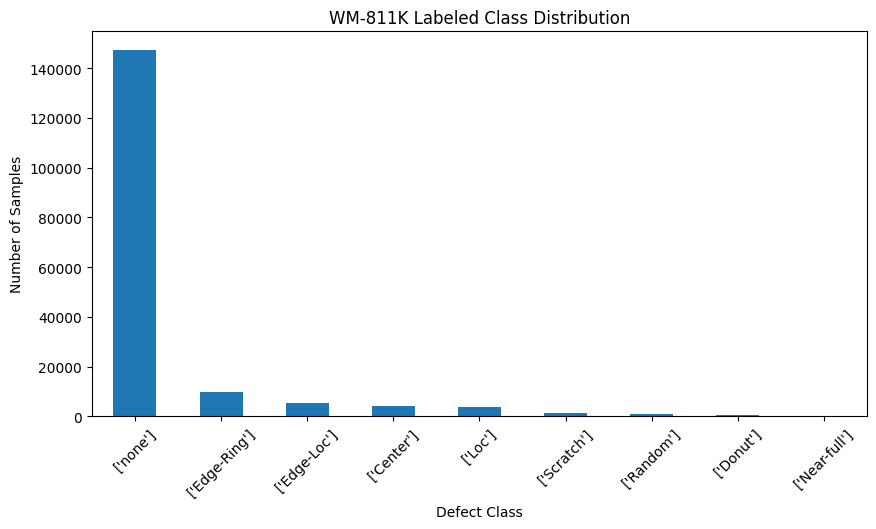

In [ ]:
plt.figure(figsize=(10, 5))

class_counts.plot(kind="bar")

plt.title("WM-811K Labeled Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

In [ ]:
classes = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Random",
    "Scratch",
    "Near-Full",
    "None"
]

class_to_idx = {
    cls: i for i, cls in enumerate(classes)
}

idx_to_class = {
    i: cls for cls, i in class_to_idx.items()
}

print(class_to_idx)

{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Random': 5, 'Scratch': 6, 'Near-Full': 7, 'None': 8}


In [ ]:
labeled_df["label"] = labeled_df["class_name"].map(class_to_idx)

print(labeled_df[["class_name", "label"]].head())

  class_name  label
0   ['none']    NaN
1   ['none']    NaN
2   ['none']    NaN
3   ['none']    NaN
4   ['none']    NaN


In [ ]:
print("Class names:")
print(labeled_df["class_name"].value_counts(dropna=False))

print("\nLabel column:")
print(labeled_df["label"].value_counts(dropna=False))

print("\nMissing labels:", labeled_df["label"].isna().sum())

Class names:
class_name
['none']         147431
['Edge-Ring']      9680
['Edge-Loc']       5189
['Center']         4294
['Loc']            3593
['Scratch']        1193
['Random']          866
['Donut']           555
['Near-full']       149
Name: count, dtype: int64

Label column:
label
NaN    172950
Name: count, dtype: int64

Missing labels: 172950


In [ ]:
def clean_label(x):
    # Unwrap nested lists, tuples and arrays
    while isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 0:
            return np.nan
        x = x[0]

    # Missing values mean unlabeled samples
    if x is None or pd.isna(x):
        return np.nan

    label = str(x).strip().lower()

    # Normalize the nine class names
    label_map = {
        "center": "Center",
        "donut": "Donut",
        "edge-loc": "Edge-Loc",
        "edge-ring": "Edge-Ring",
        "loc": "Loc",
        "random": "Random",
        "scratch": "Scratch",
        "near-full": "Near-Full",
        "none": "None"
    }

    return label_map.get(label, np.nan)


df["class_name"] = df["failureType"].apply(clean_label)

print(df["class_name"].value_counts(dropna=False))

class_name
NaN          638507
None         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-Full       149
Name: count, dtype: int64


In [ ]:
classes = [
    "Center", "Donut", "Edge-Loc", "Edge-Ring",
    "Loc", "Random", "Scratch", "Near-Full", "None"
]

class_to_idx = {name: i for i, name in enumerate(classes)}

labeled_df = df[df["class_name"].notna()].copy()

labeled_df["label"] = labeled_df["class_name"].map(class_to_idx)

print("Labeled samples:", len(labeled_df))
print("Missing numeric labels:", labeled_df["label"].isna().sum())
print("Classes found:", sorted(labeled_df["class_name"].unique()))

assert labeled_df["label"].notna().all(), "Some labels are still missing!"
assert set(labeled_df["class_name"].unique()).issubset(set(classes)), "Unexpected class names!"

Labeled samples: 172950
Missing numeric labels: 0
Classes found: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-Full', 'None', 'Random', 'Scratch']


In [ ]:
train_df, temp_df = train_test_split(
    labeled_df,
    test_size=0.30,
    stratify=labeled_df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 121065
Validation: 25942
Testing: 25943


In [ ]:
def preprocess_wafer_map(wafer_map, size=64):

    # Convert to numpy
    img = np.array(wafer_map, dtype=np.float32)

    # Normalize
    if img.max() > 0:
        img = img / img.max()

    # Convert to tensor
    img = torch.tensor(img, dtype=torch.float32)

    # Add channel dimension
    img = img.unsqueeze(0)

    # Resize to fixed size
    img = F.interpolate(
        img.unsqueeze(0),
        size=(size, size),
        mode="nearest"
    )

    img = img.squeeze(0)

    return img

In [ ]:
class WaferDataset(Dataset):

    def __init__(self, dataframe, has_labels=True):

        self.dataframe = dataframe.reset_index(drop=True)
        self.has_labels = has_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        wafer_map = preprocess_wafer_map(row["waferMap"])

        if self.has_labels:
            label = torch.tensor(
                int(row["label"]),
                dtype=torch.long
            )

            return wafer_map, label

        else:
            return wafer_map

In [ ]:
BATCH_SIZE = 64

train_dataset = WaferDataset(train_df)
val_dataset = WaferDataset(val_df)
test_dataset = WaferDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


In [ ]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels:", labels[:10])

Image shape: torch.Size([64, 1, 64, 64])
Labels: tensor([8, 8, 8, 8, 8, 8, 8, 3, 8, 8])


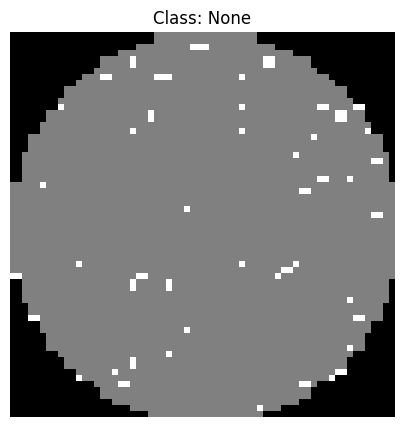

In [ ]:
plt.figure(figsize=(5,5))

plt.imshow(images[0].squeeze(), cmap="gray")

plt.title(
    "Class: " + idx_to_class[labels[0].item()]
)

plt.axis("off")

plt.show()

In [ ]:
class WaferCNN(nn.Module):

    def __init__(self, num_classes=9):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 8 * 8,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [ ]:
model = WaferCNN(num_classes=9).to(device)

print(model)

WaferCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)


In [ ]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

output = model(sample_images)

print("Output shape:", output.shape)

Output shape: torch.Size([64, 9])


In [ ]:
model_baseline = WaferCNN(num_classes=9).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_baseline.parameters(),
    lr=0.001
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def validate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    loss = running_loss / total
    accuracy = correct / total

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return loss, accuracy, macro_f1

In [ ]:
EPOCHS = 10

baseline_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_baseline,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, val_f1 = validate(
        model_baseline,
        val_loader,
        criterion
    )

    baseline_history["train_loss"].append(train_loss)
    baseline_history["train_accuracy"].append(train_acc)

    baseline_history["val_loss"].append(val_loss)
    baseline_history["val_accuracy"].append(val_acc)
    baseline_history["val_macro_f1"].append(val_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

Epoch 1/10 | Train Loss: 0.2115 | Train Acc: 0.9433 | Val Acc: 0.9623 | Val Macro-F1: 0.7147
Epoch 2/10 | Train Loss: 0.1071 | Train Acc: 0.9668 | Val Acc: 0.9660 | Val Macro-F1: 0.7798
Epoch 3/10 | Train Loss: 0.0862 | Train Acc: 0.9721 | Val Acc: 0.9706 | Val Macro-F1: 0.8017
Epoch 4/10 | Train Loss: 0.0664 | Train Acc: 0.9775 | Val Acc: 0.9692 | Val Macro-F1: 0.8302
Epoch 5/10 | Train Loss: 0.0489 | Train Acc: 0.9833 | Val Acc: 0.9662 | Val Macro-F1: 0.7985
Epoch 6/10 | Train Loss: 0.0328 | Train Acc: 0.9885 | Val Acc: 0.9680 | Val Macro-F1: 0.8356
Epoch 7/10 | Train Loss: 0.0251 | Train Acc: 0.9914 | Val Acc: 0.9677 | Val Macro-F1: 0.8327
Epoch 8/10 | Train Loss: 0.0197 | Train Acc: 0.9931 | Val Acc: 0.9663 | Val Macro-F1: 0.8333
Epoch 9/10 | Train Loss: 0.0160 | Train Acc: 0.9945 | Val Acc: 0.9687 | Val Macro-F1: 0.8381
Epoch 10/10 | Train Loss: 0.0151 | Train Acc: 0.9952 | Val Acc: 0.9684 | Val Macro-F1: 0.8223


In [ ]:
def get_predictions(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    return all_labels, all_predictions


baseline_labels, baseline_predictions = get_predictions(
    model_baseline,
    val_loader
)

print("Predictions collected successfully!")

Predictions collected successfully!


<Figure size 1100x900 with 0 Axes>

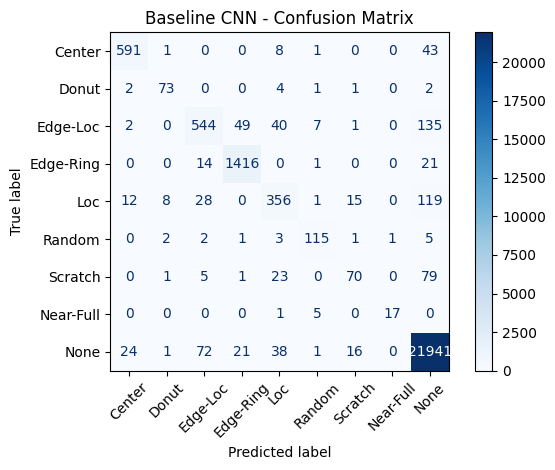

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_baseline = confusion_matrix(
    baseline_labels,
    baseline_predictions,
    labels=list(range(9))
)

plt.figure(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=classes
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Baseline CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        baseline_labels,
        baseline_predictions,
        labels=list(range(9)),
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Center       0.94      0.92      0.93       644
       Donut       0.85      0.88      0.86        83
    Edge-Loc       0.82      0.70      0.75       778
   Edge-Ring       0.95      0.98      0.96      1452
         Loc       0.75      0.66      0.70       539
      Random       0.87      0.88      0.88       130
     Scratch       0.67      0.39      0.49       179
   Near-Full       0.94      0.74      0.83        23
        None       0.98      0.99      0.99     22114

    accuracy                           0.97     25942
   macro avg       0.86      0.79      0.82     25942
weighted avg       0.97      0.97      0.97     25942



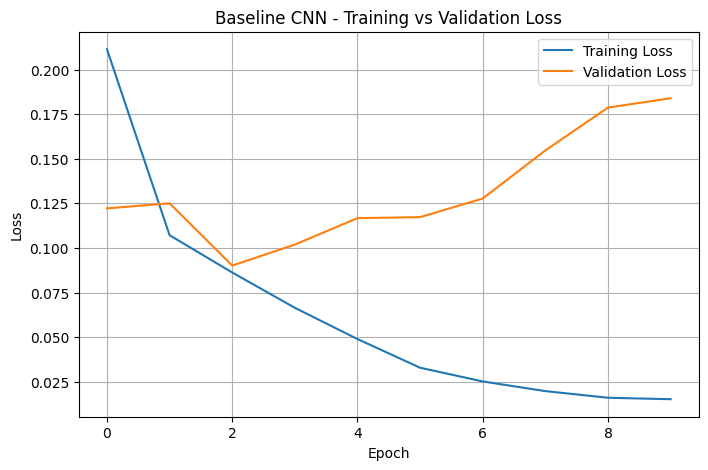

In [ ]:
# Training and Validation Loss

plt.figure(figsize=(8,5))

plt.plot(baseline_history["train_loss"], label="Training Loss")
plt.plot(baseline_history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

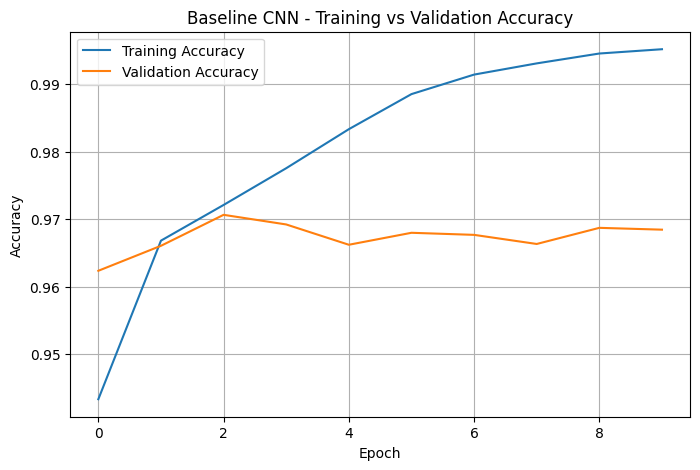

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(baseline_history["train_accuracy"], label="Training Accuracy")
plt.plot(baseline_history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN - Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
torch.save(
    model_baseline.state_dict(),
    "/content/baseline_cnn.pth"
)

print("Baseline CNN model saved successfully!")

Baseline CNN model saved successfully!


In [ ]:
baseline_report = classification_report(
    baseline_labels,
    baseline_predictions,
    labels=list(range(9)),
    target_names=classes,
    zero_division=0,
    output_dict=True
)

baseline_report_df = pd.DataFrame(baseline_report).transpose()

baseline_report_df.to_csv(
    "/content/baseline_classification_report.csv"
)

print("Baseline classification report saved!")

Baseline classification report saved!


FOCAL LOSS

In [ ]:
class FocalLoss(nn.Module):

    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()

        self.gamma = gamma
        self.alpha = alpha

    def forward(self, logits, targets):

        log_probs = F.log_softmax(logits, dim=1)
        probs = torch.exp(log_probs)

        # Probability of the actual class
        pt = probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        # Focal Loss focusing factor
        focal_factor = (1 - pt) ** self.gamma

        loss = -focal_factor * log_pt

        # Optional class weighting
        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()

In [ ]:
model_focal = WaferCNN(num_classes=9).to(device)

focal_criterion = FocalLoss(
    gamma=2.0,
    alpha=None
)

focal_optimizer = torch.optim.Adam(
    model_focal.parameters(),
    lr=0.001
)

print("Focal Loss model initialized successfully!")

Focal Loss model initialized successfully!


In [ ]:
focal_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_focal,
        train_loader,
        focal_criterion,
        focal_optimizer
    )

    val_loss, val_acc, val_f1 = validate(
        model_focal,
        val_loader,
        focal_criterion
    )

    focal_history["train_loss"].append(train_loss)
    focal_history["train_accuracy"].append(train_acc)
    focal_history["val_loss"].append(val_loss)
    focal_history["val_accuracy"].append(val_acc)
    focal_history["val_macro_f1"].append(val_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

Epoch 1/10 | Train Loss: 0.1033 | Train Acc: 0.9449 | Val Loss: 0.0608 | Val Acc: 0.9613 | Val Macro-F1: 0.6385
Epoch 2/10 | Train Loss: 0.0510 | Train Acc: 0.9648 | Val Loss: 0.0450 | Val Acc: 0.9672 | Val Macro-F1: 0.7945
Epoch 3/10 | Train Loss: 0.0398 | Train Acc: 0.9702 | Val Loss: 0.0469 | Val Acc: 0.9630 | Val Macro-F1: 0.7807
Epoch 4/10 | Train Loss: 0.0302 | Train Acc: 0.9745 | Val Loss: 0.0453 | Val Acc: 0.9673 | Val Macro-F1: 0.7981
Epoch 5/10 | Train Loss: 0.0222 | Train Acc: 0.9798 | Val Loss: 0.0463 | Val Acc: 0.9694 | Val Macro-F1: 0.8306
Epoch 6/10 | Train Loss: 0.0149 | Train Acc: 0.9851 | Val Loss: 0.0456 | Val Acc: 0.9709 | Val Macro-F1: 0.8382
Epoch 7/10 | Train Loss: 0.0110 | Train Acc: 0.9883 | Val Loss: 0.0528 | Val Acc: 0.9668 | Val Macro-F1: 0.8345
Epoch 8/10 | Train Loss: 0.0083 | Train Acc: 0.9914 | Val Loss: 0.0637 | Val Acc: 0.9652 | Val Macro-F1: 0.8176
Epoch 9/10 | Train Loss: 0.0071 | Train Acc: 0.9925 | Val Loss: 0.0613 | Val Acc: 0.9688 | Val Macro-F1:

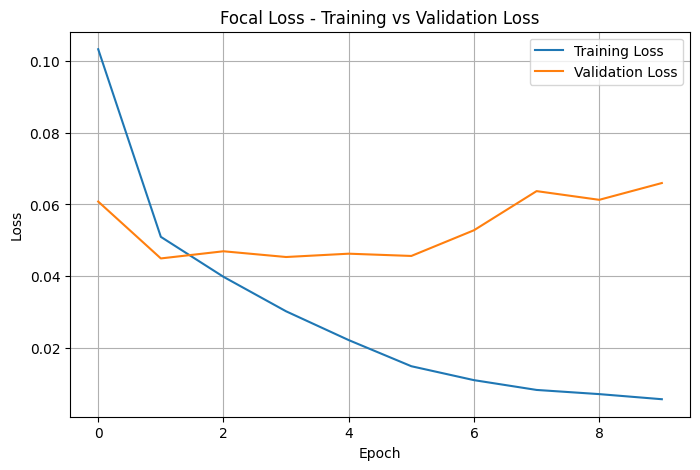

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(focal_history["train_loss"], label="Training Loss")
plt.plot(focal_history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal Loss - Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

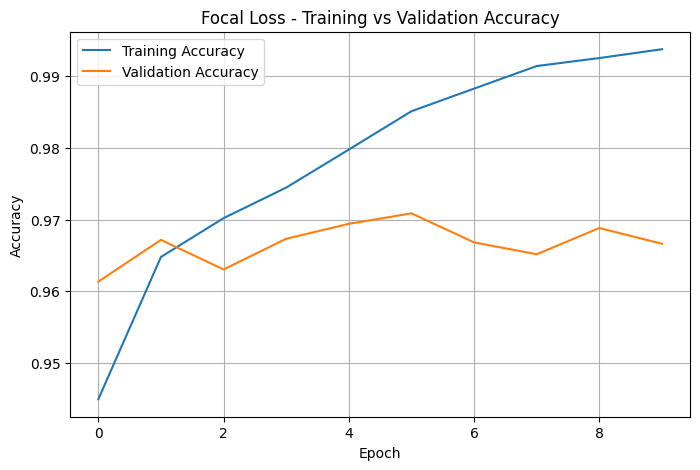

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(focal_history["train_accuracy"], label="Training Accuracy")
plt.plot(focal_history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Focal Loss - Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

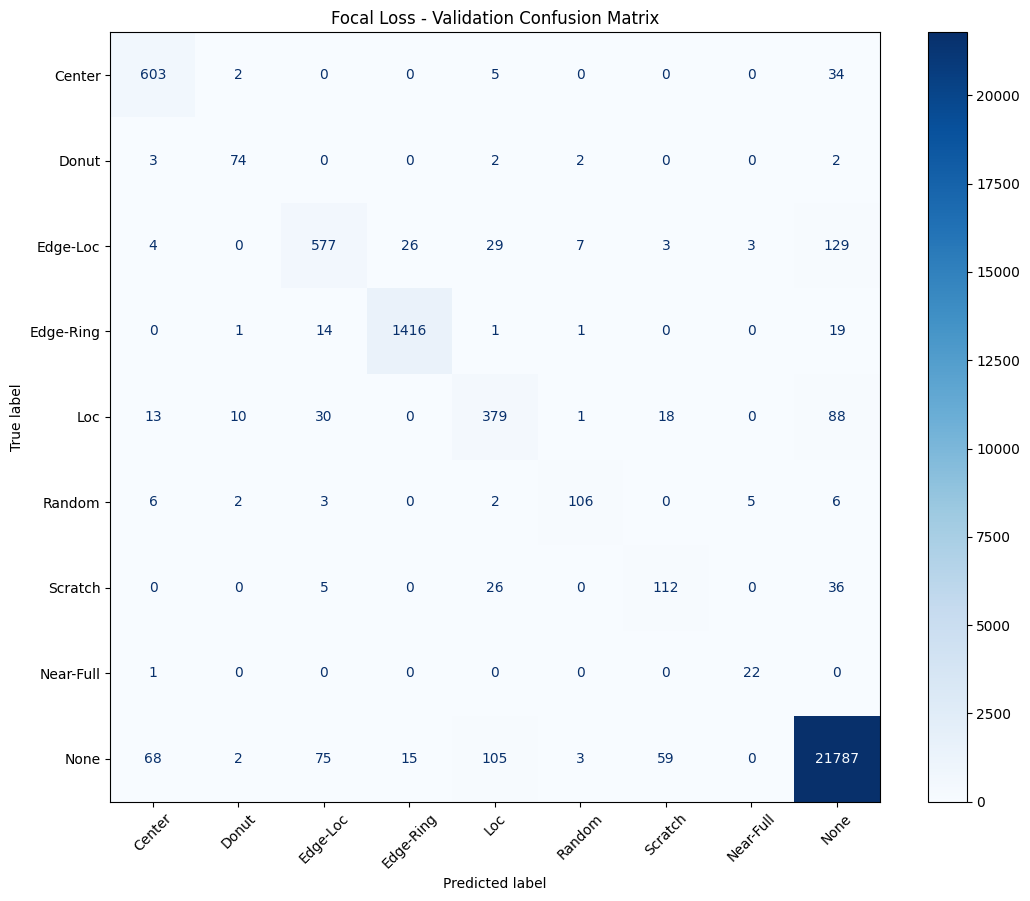

In [ ]:
focal_labels, focal_predictions = get_predictions(
    model_focal,
    val_loader
)

cm_focal = confusion_matrix(
    focal_labels,
    focal_predictions,
    labels=list(range(9))
)

fig, ax = plt.subplots(figsize=(11,9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_focal,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Focal Loss - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print(
    classification_report(
        focal_labels,
        focal_predictions,
        labels=list(range(9)),
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Center       0.86      0.94      0.90       644
       Donut       0.81      0.89      0.85        83
    Edge-Loc       0.82      0.74      0.78       778
   Edge-Ring       0.97      0.98      0.97      1452
         Loc       0.69      0.70      0.70       539
      Random       0.88      0.82      0.85       130
     Scratch       0.58      0.63      0.60       179
   Near-Full       0.73      0.96      0.83        23
        None       0.99      0.99      0.99     22114

    accuracy                           0.97     25942
   macro avg       0.82      0.85      0.83     25942
weighted avg       0.97      0.97      0.97     25942



In [ ]:
torch.save(
    model_focal.state_dict(),
    "/content/focal_loss_cnn.pth"
)

focal_report = classification_report(
    focal_labels,
    focal_predictions,
    labels=list(range(9)),
    target_names=classes,
    zero_division=0,
    output_dict=True
)

focal_report_df = pd.DataFrame(focal_report).transpose()

focal_report_df.to_csv(
    "/content/focal_loss_classification_report.csv"
)

print("Focal Loss model and report saved successfully!")

Focal Loss model and report saved successfully!


SEMI SUPERVISED LEARNING

In [ ]:
unlabeled_df = df[
    df["class_name"].isna()
].copy()

print("Total unlabeled samples:", len(unlabeled_df))

SSL_SAMPLE_SIZE = 50000

unlabeled_sample = unlabeled_df.sample(
    n=min(SSL_SAMPLE_SIZE, len(unlabeled_df)),
    random_state=42
).reset_index(drop=True)

print("Selected SSL samples:", len(unlabeled_sample))

Total unlabeled samples: 638507
Selected SSL samples: 50000


In [ ]:
class UnlabeledWaferDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        wafer_map = preprocess_wafer_map(
            row["waferMap"]
        )

        return wafer_map, index

In [ ]:
unlabeled_dataset = UnlabeledWaferDataset(
    unlabeled_sample
)

unlabeled_loader = DataLoader(
    unlabeled_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Unlabeled DataLoader created successfully!")

Unlabeled DataLoader created successfully!


In [ ]:
def generate_pseudo_labels(
    model,
    loader,
    threshold=0.95
):

    model.eval()

    all_indices = []
    all_labels = []
    all_confidences = []

    with torch.no_grad():

        for images, batch_indices in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = F.softmax(
                outputs,
                dim=1
            )

            confidence, predictions = probabilities.max(dim=1)

            # Confidence filtering
            mask = confidence >= threshold

            # Move mask to CPU for indexing batch_indices
            mask_cpu = mask.cpu()

            accepted_indices = batch_indices[mask_cpu]

            # Predictions and confidence remain on GPU
            accepted_labels = predictions[mask]
            accepted_confidences = confidence[mask]

            all_indices.extend(
                accepted_indices.tolist()
            )

            all_labels.extend(
                accepted_labels.cpu().tolist()
            )

            all_confidences.extend(
                accepted_confidences.cpu().tolist()
            )

    return (
        all_indices,
        all_labels,
        all_confidences
    )

In [ ]:
indices, pseudo_labels, confidences = generate_pseudo_labels(
    model_baseline,
    unlabeled_loader,
    threshold=0.95
)

print("Total unlabeled samples:", len(unlabeled_sample))

print("Accepted pseudo-labels:", len(pseudo_labels))

print(
    "Rejected samples:",
    len(unlabeled_sample) - len(pseudo_labels)
)

Total unlabeled samples: 50000
Accepted pseudo-labels: 44357
Rejected samples: 5643


In [ ]:
from collections import Counter

pseudo_counts = Counter(pseudo_labels)

print("Pseudo-label distribution:\n")

for class_idx in range(9):

    count = pseudo_counts.get(class_idx, 0)

    print(
        f"{idx_to_class[class_idx]}: {count}"
    )

Pseudo-label distribution:

Center: 1291
Donut: 18
Edge-Loc: 774
Edge-Ring: 732
Loc: 329
Random: 367
Scratch: 159
Near-Full: 4631
None: 36056


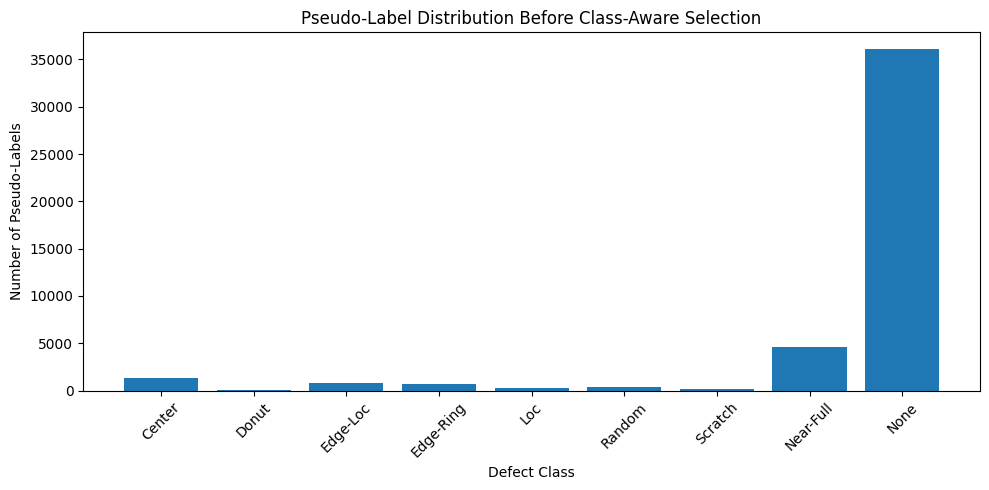

In [ ]:
pseudo_class_names = [
    idx_to_class[i] for i in range(9)
]

pseudo_class_values = [
    pseudo_counts.get(i, 0) for i in range(9)
]

plt.figure(figsize=(10,5))

plt.bar(
    pseudo_class_names,
    pseudo_class_values
)

plt.xlabel("Defect Class")
plt.ylabel("Number of Pseudo-Labels")
plt.title("Pseudo-Label Distribution Before Class-Aware Selection")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def class_aware_selection(
    indices,
    labels,
    confidences,
    max_per_class=2000
):

    selected_indices = []
    selected_labels = []
    selected_confidences = []

    class_counter = Counter()

    # Process highest-confidence predictions first
    order = np.argsort(confidences)[::-1]

    for i in order:

        label = labels[i]

        if class_counter[label] < max_per_class:

            selected_indices.append(indices[i])
            selected_labels.append(labels[i])
            selected_confidences.append(confidences[i])

            class_counter[label] += 1

    return (
        selected_indices,
        selected_labels,
        selected_confidences
    )

In [ ]:
selected_indices, selected_labels, selected_confidences = (
    class_aware_selection(
        indices,
        pseudo_labels,
        confidences,
        max_per_class=2000
    )
)

print("Accepted before selection:", len(pseudo_labels))

print("Selected after class-aware selection:", len(selected_labels))

print("\nFinal class distribution:")

for class_idx in range(9):

    print(
        idx_to_class[class_idx],
        ":",
        selected_labels.count(class_idx)
    )

Accepted before selection: 44357
Selected after class-aware selection: 7670

Final class distribution:
Center : 1291
Donut : 18
Edge-Loc : 774
Edge-Ring : 732
Loc : 329
Random : 367
Scratch : 159
Near-Full : 2000
None : 2000


In [ ]:
pseudo_rows = []

for idx, label, confidence in zip(
    selected_indices,
    selected_labels,
    selected_confidences
):

    row = unlabeled_sample.iloc[idx].copy()

    row["label"] = int(label)

    row["class_name"] = idx_to_class[label]

    row["confidence"] = confidence

    pseudo_rows.append(row)

pseudo_df = pd.DataFrame(pseudo_rows)

print("Pseudo-labeled dataframe shape:", pseudo_df.shape)

display(
    pseudo_df[
        ["class_name", "label", "confidence"]
    ].head()
)

Pseudo-labeled dataframe shape: (7670, 9)


,class_name,label,confidence
47,None,8,1.0
50,None,8,1.0
56,None,8,1.0
57,None,8,1.0
21,None,8,1.0


In [ ]:
ssl_train_df = pd.concat(
    [
        train_df,
        pseudo_df
    ],
    ignore_index=True
)

print("Original training samples:", len(train_df))

print("Pseudo-labeled samples:", len(pseudo_df))

print("Final SSL training samples:", len(ssl_train_df))

Original training samples: 121065
Pseudo-labeled samples: 7670
Final SSL training samples: 128735


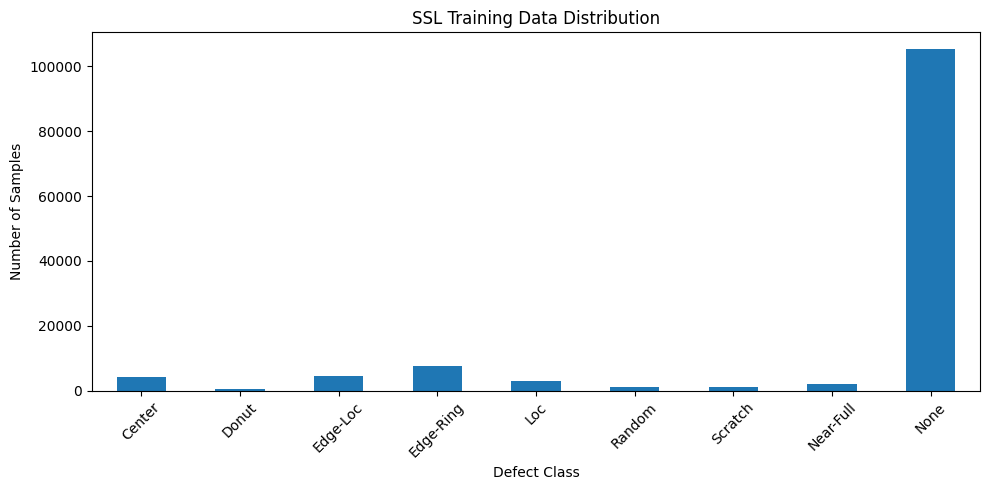

In [ ]:
plt.figure(figsize=(10,5))

ssl_train_df["class_name"].value_counts().reindex(
    classes,
    fill_value=0
).plot(kind="bar")

plt.xlabel("Defect Class")
plt.ylabel("Number of Samples")
plt.title("SSL Training Data Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
ssl_dataset = WaferDataset(
    ssl_train_df,
    has_labels=True
)

ssl_loader = DataLoader(
    ssl_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("SSL DataLoader created successfully!")

SSL DataLoader created successfully!


In [ ]:
model_ssl = WaferCNN(num_classes=9).to(device)

ssl_criterion = nn.CrossEntropyLoss()

ssl_optimizer = torch.optim.Adam(
    model_ssl.parameters(),
    lr=0.001
)

print("SSL model initialized successfully!")

SSL model initialized successfully!


In [ ]:
SSL_EPOCHS = EPOCHS

ssl_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(SSL_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_ssl,
        ssl_loader,
        ssl_criterion,
        ssl_optimizer
    )

    val_loss, val_acc, val_f1 = validate(
        model_ssl,
        val_loader,
        ssl_criterion
    )

    ssl_history["train_loss"].append(train_loss)
    ssl_history["train_accuracy"].append(train_acc)
    ssl_history["val_loss"].append(val_loss)
    ssl_history["val_accuracy"].append(val_acc)
    ssl_history["val_macro_f1"].append(val_f1)

    print(
        f"Epoch {epoch+1}/{SSL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

Epoch 1/10 | Train Loss: 0.2325 | Train Acc: 0.9365 | Val Loss: 0.1336 | Val Acc: 0.9624 | Val Macro-F1: 0.7419
Epoch 2/10 | Train Loss: 0.1140 | Train Acc: 0.9643 | Val Loss: 0.1260 | Val Acc: 0.9632 | Val Macro-F1: 0.7624
Epoch 3/10 | Train Loss: 0.0911 | Train Acc: 0.9706 | Val Loss: 0.1289 | Val Acc: 0.9664 | Val Macro-F1: 0.7798
Epoch 4/10 | Train Loss: 0.0757 | Train Acc: 0.9747 | Val Loss: 0.0922 | Val Acc: 0.9707 | Val Macro-F1: 0.8284
Epoch 5/10 | Train Loss: 0.0578 | Train Acc: 0.9806 | Val Loss: 0.1077 | Val Acc: 0.9709 | Val Macro-F1: 0.8164
Epoch 6/10 | Train Loss: 0.0436 | Train Acc: 0.9847 | Val Loss: 0.1035 | Val Acc: 0.9693 | Val Macro-F1: 0.8440
Epoch 7/10 | Train Loss: 0.0322 | Train Acc: 0.9886 | Val Loss: 0.1328 | Val Acc: 0.9701 | Val Macro-F1: 0.8316
Epoch 8/10 | Train Loss: 0.0240 | Train Acc: 0.9916 | Val Loss: 0.1458 | Val Acc: 0.9623 | Val Macro-F1: 0.8191
Epoch 9/10 | Train Loss: 0.0195 | Train Acc: 0.9934 | Val Loss: 0.1557 | Val Acc: 0.9692 | Val Macro-F1:

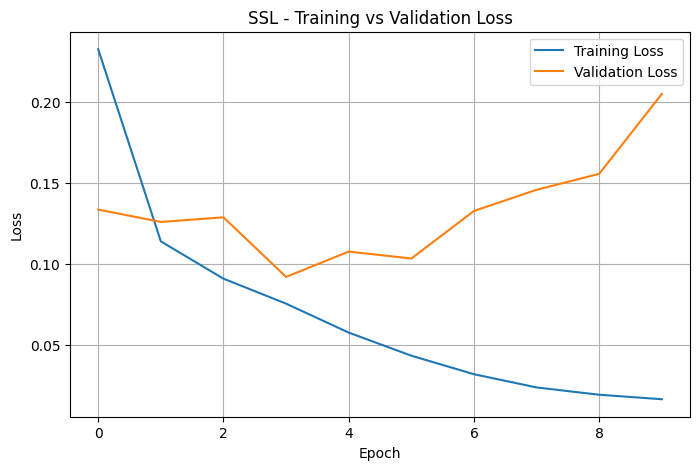

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(ssl_history["train_loss"], label="Training Loss")
plt.plot(ssl_history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SSL - Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

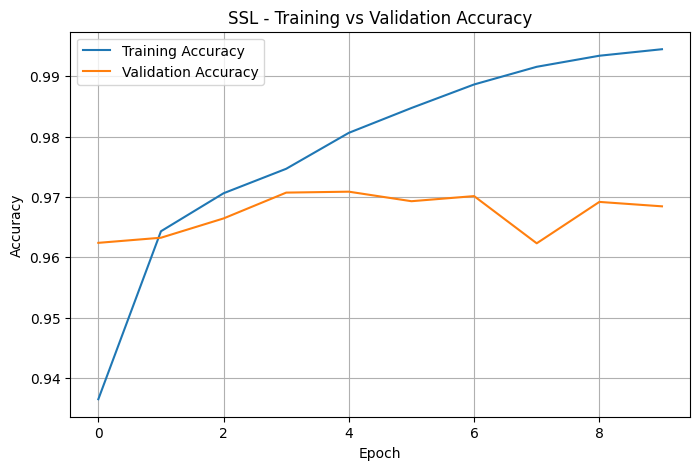

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(ssl_history["train_accuracy"], label="Training Accuracy")
plt.plot(ssl_history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SSL - Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

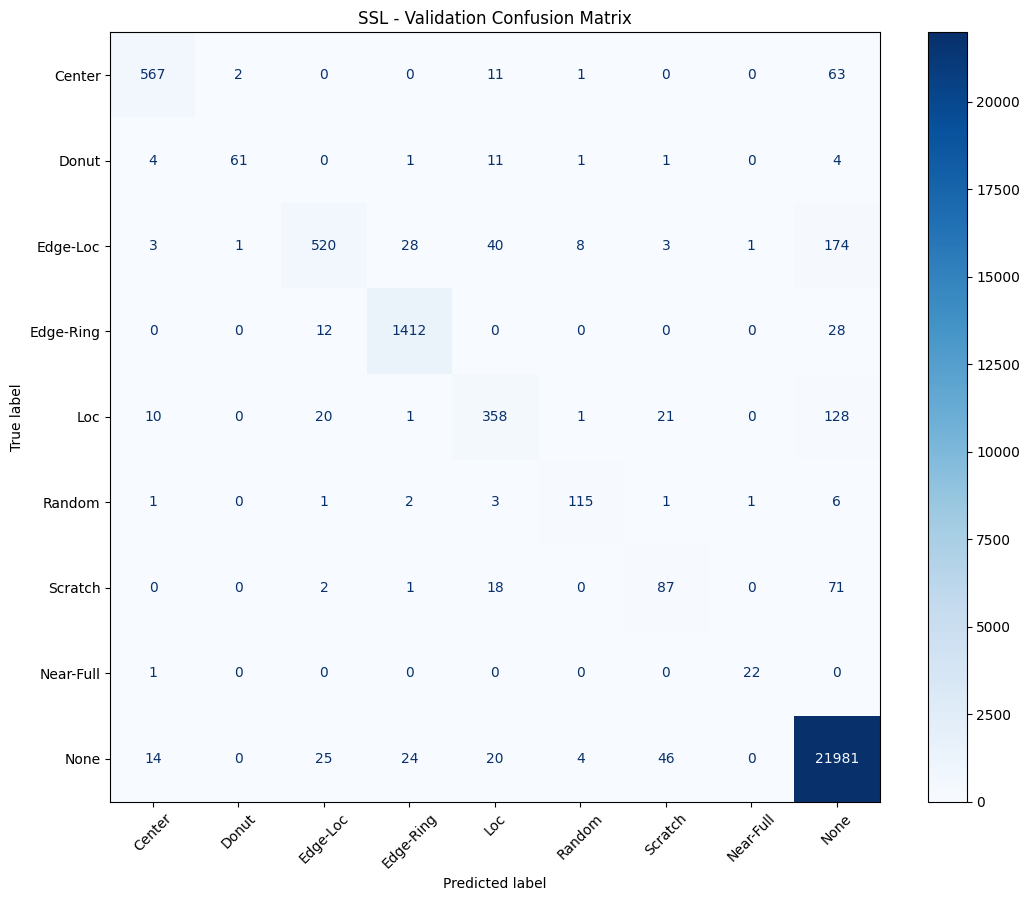

In [ ]:
ssl_labels, ssl_predictions = get_predictions(
    model_ssl,
    val_loader
)

cm_ssl = confusion_matrix(
    ssl_labels,
    ssl_predictions,
    labels=list(range(9))
)

fig, ax = plt.subplots(figsize=(11,9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ssl,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("SSL - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print(
    classification_report(
        ssl_labels,
        ssl_predictions,
        labels=list(range(9)),
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Center       0.94      0.88      0.91       644
       Donut       0.95      0.73      0.83        83
    Edge-Loc       0.90      0.67      0.77       778
   Edge-Ring       0.96      0.97      0.97      1452
         Loc       0.78      0.66      0.72       539
      Random       0.88      0.88      0.88       130
     Scratch       0.55      0.49      0.51       179
   Near-Full       0.92      0.96      0.94        23
        None       0.98      0.99      0.99     22114

    accuracy                           0.97     25942
   macro avg       0.87      0.80      0.83     25942
weighted avg       0.97      0.97      0.97     25942



In [ ]:
torch.save(
    model_ssl.state_dict(),
    "/content/ssl_cnn.pth"
)

ssl_report = classification_report(
    ssl_labels,
    ssl_predictions,
    labels=list(range(9)),
    target_names=classes,
    zero_division=0,
    output_dict=True
)

ssl_report_df = pd.DataFrame(ssl_report).transpose()

ssl_report_df.to_csv(
    "/content/ssl_classification_report.csv"
)

print("SSL model and report saved successfully!")

SSL model and report saved successfully!


EVALUATION

In [ ]:
def evaluate_model(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": macro_f1,
        "labels": all_labels,
        "predictions": all_predictions
    }

In [ ]:
baseline_results = evaluate_model(
    model_baseline,
    test_loader
)

print("Baseline CNN Test Results")
print("Accuracy:", baseline_results["accuracy"])
print("Precision:", baseline_results["precision"])
print("Recall:", baseline_results["recall"])
print("Macro-F1:", baseline_results["macro_f1"])

Baseline CNN Test Results
Accuracy: 0.9690475272713256
Precision: 0.8651369474460114
Recall: 0.7952110009999197
Macro-F1: 0.8246854155528368


In [ ]:
focal_results = evaluate_model(
    model_focal,
    test_loader
)

print("Focal Loss Test Results")
print("Accuracy:", focal_results["accuracy"])
print("Precision:", focal_results["precision"])
print("Recall:", focal_results["recall"])
print("Macro-F1:", focal_results["macro_f1"])

Focal Loss Test Results
Accuracy: 0.9668118567629033
Precision: 0.8168579820932509
Recall: 0.8402116475184142
Macro-F1: 0.8249776113191258


In [ ]:
ssl_results = evaluate_model(
    model_ssl,
    test_loader
)

print("SSL Test Results")
print("Accuracy:", ssl_results["accuracy"])
print("Precision:", ssl_results["precision"])
print("Recall:", ssl_results["recall"])
print("Macro-F1:", ssl_results["macro_f1"])

SSL Test Results
Accuracy: 0.9690860733145743
Precision: 0.8604288918873401
Recall: 0.7995433648563632
Macro-F1: 0.825079717148437


In [ ]:
comparison = pd.DataFrame({

    "Model": [
        "Baseline CNN",
        "Focal Loss",
        "Semi-Supervised Learning"
    ],

    "Accuracy": [
        baseline_results["accuracy"],
        focal_results["accuracy"],
        ssl_results["accuracy"]
    ],

    "Precision": [
        baseline_results["precision"],
        focal_results["precision"],
        ssl_results["precision"]
    ],

    "Recall": [
        baseline_results["recall"],
        focal_results["recall"],
        ssl_results["recall"]
    ],

    "Macro-F1": [
        baseline_results["macro_f1"],
        focal_results["macro_f1"],
        ssl_results["macro_f1"]
    ]

})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,Macro-F1
0,Baseline CNN,0.9690,0.8651,0.7952,0.8247
1,Focal Loss,0.9668,0.8169,0.8402,0.8250
2,Semi-Supervised Learning,0.9691,0.8604,0.7995,0.8251


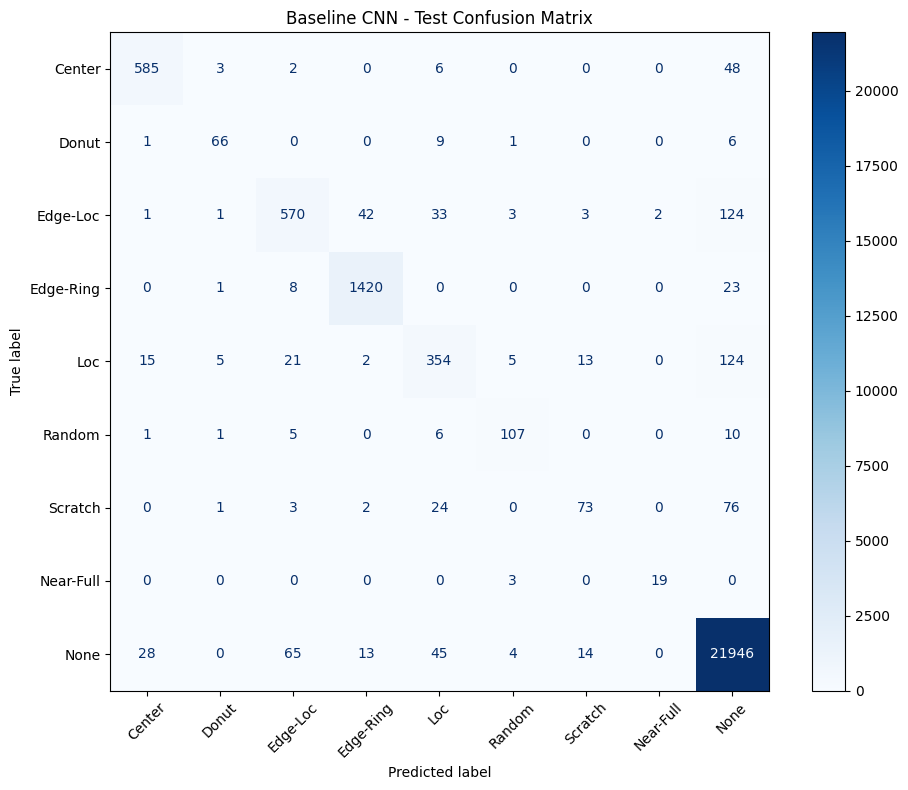

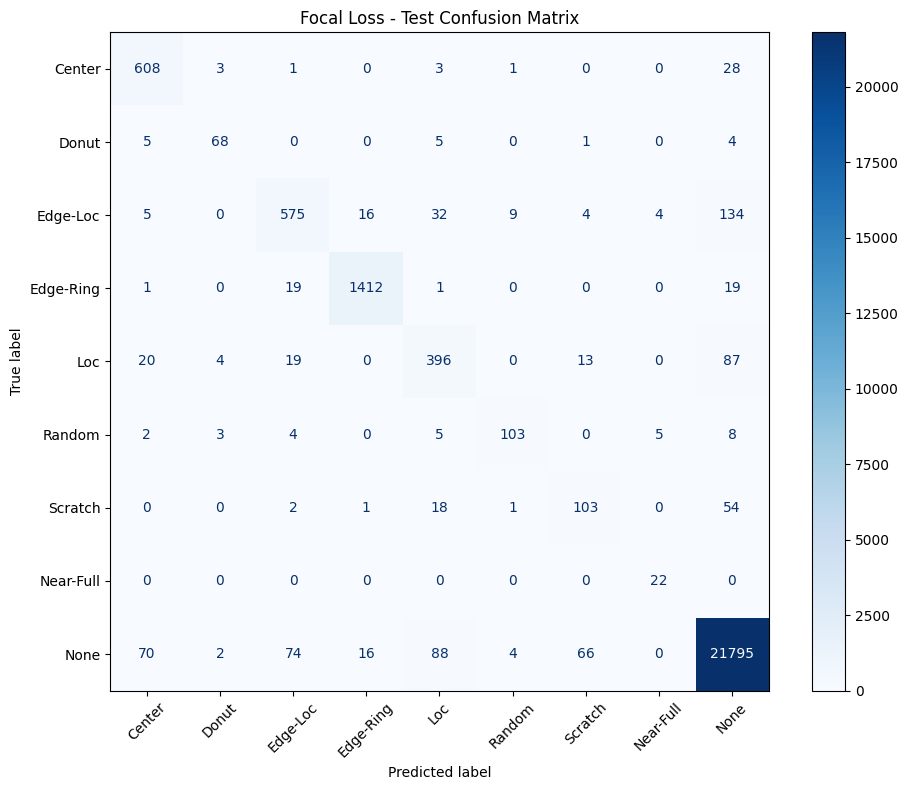

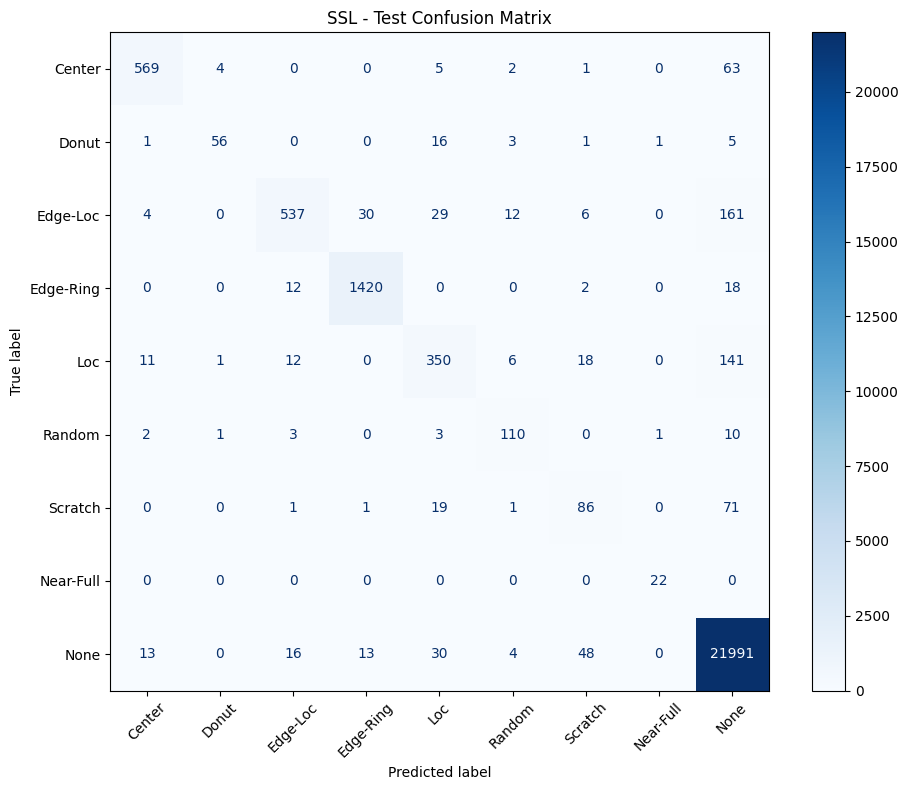

In [ ]:
results_dict = {
    "Baseline CNN": baseline_results,
    "Focal Loss": focal_results,
    "SSL": ssl_results
}

for model_name, result in results_dict.items():

    cm = confusion_matrix(
        result["labels"],
        result["predictions"],
        labels=list(range(9))
    )

    fig, ax = plt.subplots(figsize=(10,8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d"
    )

    plt.title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

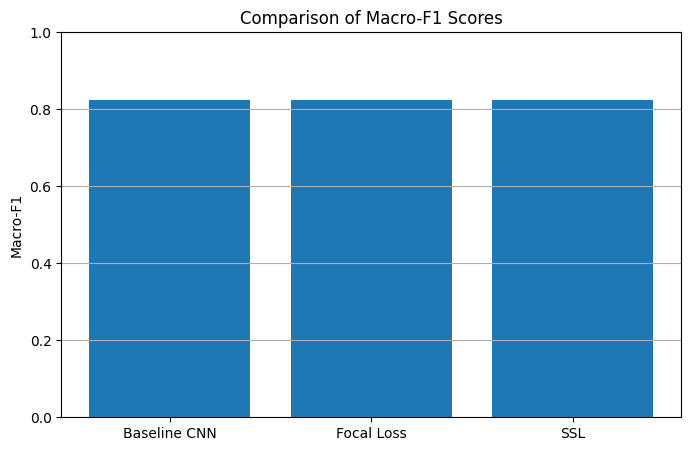

In [ ]:
model_names = [
    "Baseline CNN",
    "Focal Loss",
    "SSL"
]

macro_f1_values = [
    baseline_results["macro_f1"],
    focal_results["macro_f1"],
    ssl_results["macro_f1"]
]

plt.figure(figsize=(8,5))

plt.bar(
    model_names,
    macro_f1_values
)

plt.ylabel("Macro-F1")
plt.title("Comparison of Macro-F1 Scores")

plt.ylim(0,1)
plt.grid(axis="y")
plt.show()

In [ ]:
baseline_f1 = f1_score(
    baseline_results["labels"],
    baseline_results["predictions"],
    labels=list(range(9)),
    average=None,
    zero_division=0
)

focal_f1 = f1_score(
    focal_results["labels"],
    focal_results["predictions"],
    labels=list(range(9)),
    average=None,
    zero_division=0
)

ssl_f1 = f1_score(
    ssl_results["labels"],
    ssl_results["predictions"],
    labels=list(range(9)),
    average=None,
    zero_division=0
)

per_class_comparison = pd.DataFrame({
    "Class": classes,
    "Baseline F1": baseline_f1,
    "Focal Loss F1": focal_f1,
    "SSL F1": ssl_f1
})

display(per_class_comparison.round(4))

,Class,Baseline F1,Focal Loss F1,SSL F1
0,Center,0.9176,0.8974,0.9148
1,Donut,0.8199,0.8344,0.7724
2,Edge-Loc,0.7846,0.7807,0.7897
3,Edge-Ring,0.9690,0.9748,0.9739
4,Loc,0.6969,0.7286,0.7064
5,Random,0.8458,0.8306,0.8209
6,Scratch,0.5177,0.5628,0.5044
7,Near-Full,0.8837,0.8302,0.9565
8,None,0.9870,0.9852,0.9867


In [ ]:
comparison.to_csv(
    "/content/phase1_final_comparison.csv",
    index=False
)

per_class_comparison.to_csv(
    "/content/phase1_per_class_comparison.csv",
    index=False
)

print("Final comparison files saved successfully!")

Final comparison files saved successfully!


In [ ]:
from google.colab import files

files.download("/content/phase1_final_comparison.csv")

files.download("/content/phase1_per_class_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>